# 02 — Exploratory Data Analysis: Insurance Claim Fraud Patterns

## Objective
Explore historical claim characteristics and identify **associations** with the fraud target (`FraudFound_P`). We will not infer causality or treat a feature as proof of fraud. Findings will inform hypotheses and later feature engineering.

**Target:** `FraudFound_P` (1 = fraud, 0 = legitimate).

**Questions:**
1. What is the fraud prevalence?
2. Which categorical features have different fraud rates?
3. How do numeric features compare across fraud/legitimate groups?
4. Do claim and accident timing variables reveal patterns or data quality issues?
5. Which findings merit validation or feature engineering?

## 1. Imports and project setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

%matplotlib inline
sns.set_theme()
plt.rcParams["figure.figsize"] = (10, 5)

PROJECT_ROOT = Path.cwd()
# If the notebook is launched from notebooks/, move one level up.
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "fraud_oracle.csv"

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)

Project root: c:\Users\rudra\OneDrive\Documents\insurance-claim-fraud-detection\insurance-claim-fraud-detection
Dataset path: c:\Users\rudra\OneDrive\Documents\insurance-claim-fraud-detection\insurance-claim-fraud-detection\data\raw\fraud_oracle.csv


## 2. Load data and confirm target

In [2]:
df = pd.read_csv(DATA_PATH)
TARGET = "FraudFound_P"

print("Shape:", df.shape)
display(df.head())
assert TARGET in df.columns, f"Target column {TARGET!r} not found"
assert set(df[TARGET].dropna().unique()).issubset({0, 1}), "Unexpected target labels"

Shape: (15420, 33)


,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,...,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,...,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,...,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,...,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,...,more than 7,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,...,5 years,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision


## 3. Target distribution and baseline

,count,percentage
FraudFound_P,,
Legitimate (0),14497,94.014267
Fraud (1),923,5.985733


Fraud prevalence: 5.99%
Majority-class accuracy baseline: 94.01%


C:\Users\rudra\AppData\Local\Temp\ipykernel_32328\3214748851.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Legitimate (0)", "Fraud (1)"])


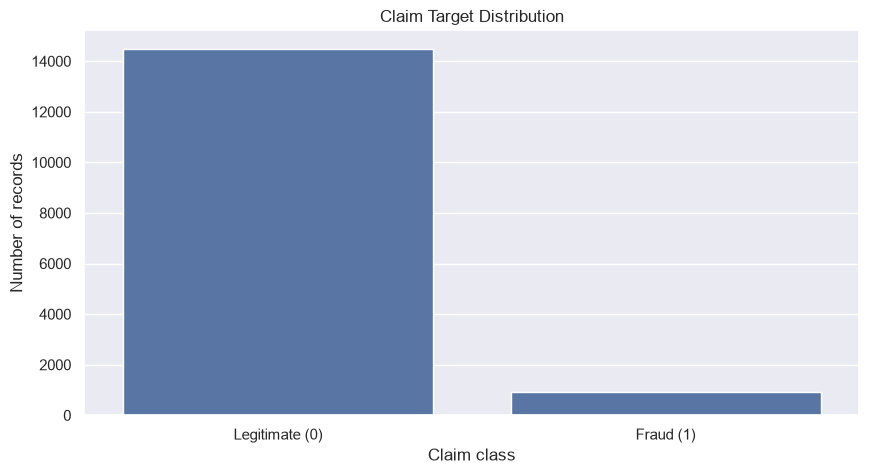

In [3]:
target_counts = df[TARGET].value_counts().sort_index()
target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": target_counts / len(df) * 100
})
target_summary.index = target_summary.index.map({0: "Legitimate (0)", 1: "Fraud (1)"})
display(target_summary)

fraud_rate = df[TARGET].mean()
print(f"Fraud prevalence: {fraud_rate:.2%}")
print(f"Majority-class accuracy baseline: {(1-fraud_rate):.2%}")

ax = sns.countplot(data=df, x=TARGET)
ax.set_xticklabels(["Legitimate (0)", "Fraud (1)"])
ax.set_title("Claim Target Distribution")
ax.set_xlabel("Claim class")
ax.set_ylabel("Number of records")
plt.show()

## 4. Fraud rates across categorical features

For each category, calculate its sample size and fraud rate. Fraud rates from very small groups can be unstable, so we display category counts and use a minimum support threshold for ranking. We exclude the target and ID-like fields from this analysis.

In [4]:
categorical_features = df.select_dtypes(include=["object", "category"]).columns.tolist()

# ID-like / high-cardinality columns are not useful for simple category-rate comparisons.
exclude_cat = {"PolicyNumber", "RepNumber"}
cat_features_for_eda = [c for c in categorical_features if c not in exclude_cat]

MIN_CATEGORY_COUNT = 50
category_rate_tables = {}

for feature in cat_features_for_eda:
    summary = (
        df.groupby(feature, dropna=False)[TARGET]
          .agg(claim_count="size", fraud_count="sum", fraud_rate="mean")
          .sort_values("fraud_rate", ascending=False)
    )
    summary["fraud_rate_pct"] = summary["fraud_rate"] * 100
    category_rate_tables[feature] = summary

print(f"Categorical features examined: {len(cat_features_for_eda)}")
print("Features:", cat_features_for_eda)

Categorical features examined: 24
Features: ['Month', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'Sex', 'MaritalStatus', 'Fault', 'PolicyType', 'VehicleCategory', 'VehiclePrice', 'Days_Policy_Accident', 'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfSuppliments', 'AddressChange_Claim', 'NumberOfCars', 'BasePolicy']


C:\Users\rudra\AppData\Local\Temp\ipykernel_32328\648615623.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include=["object", "category"]).columns.tolist()


### 4.1 Summary tables for categorical features

In [5]:
for feature, summary in category_rate_tables.items():
    print(f"\n--- {feature} ---")
    display(summary.sort_values("claim_count", ascending=False))


--- Month ---


,claim_count,fraud_count,fraud_rate,fraud_rate_pct
Month,,,,
Jan,1411,87,0.061658,6.165840
May,1367,94,0.068764,6.876372
Mar,1360,102,0.075000,7.500000
Jun,1321,80,0.060560,6.056018
Oct,1305,70,0.053640,5.363985
Dec,1285,62,0.048249,4.824903
Apr,1280,80,0.062500,6.250000
Feb,1266,82,0.064771,6.477093
Jul,1257,60,0.047733,4.773270



--- DayOfWeek ---


,claim_count,fraud_count,fraud_rate,fraud_rate_pct
DayOfWeek,,,,
Monday,2616,160,0.061162,6.116208
Friday,2445,154,0.062986,6.298569
Tuesday,2300,120,0.052174,5.217391
Thursday,2173,120,0.055223,5.522319
Wednesday,2159,115,0.053265,5.326540
Saturday,1982,132,0.066599,6.659939
Sunday,1745,122,0.069914,6.991404



--- Make ---


,claim_count,fraud_count,fraud_rate,fraud_rate_pct
Make,,,,
Pontiac,3837,213,0.055512,5.551212
Toyota,3121,186,0.059596,5.959628
Honda,2801,179,0.063906,6.390575
Mazda,2354,123,0.052251,5.225149
Chevrolet,1681,94,0.055919,5.591910
Accura,472,59,0.125000,12.500000
Ford,450,33,0.073333,7.333333
VW,283,8,0.028269,2.826855
Dodge,109,2,0.018349,1.834862


... (38 outputs left out)


--- NumberOfCars ---


,claim_count,fraud_count,fraud_rate,fraud_rate_pct
NumberOfCars,,,,
1 vehicle,14316,850,0.059374,5.937413
2 vehicles,709,43,0.060649,6.064880
3 to 4,372,29,0.077957,7.795699
5 to 8,21,1,0.047619,4.761905
more than 8,2,0,0.000000,0.000000



--- BasePolicy ---


,claim_count,fraud_count,fraud_rate,fraud_rate_pct
BasePolicy,,,,
Collision,5962,435,0.072962,7.296209
Liability,5009,36,0.007187,0.718706
All Perils,4449,452,0.101596,10.159586


### 4.2 Visualize fraud rate for selected categorical features

These plots show fraud rate by category, with category counts annotated in a companion table. Start with features that have manageable numbers of categories and meaningful business interpretation.

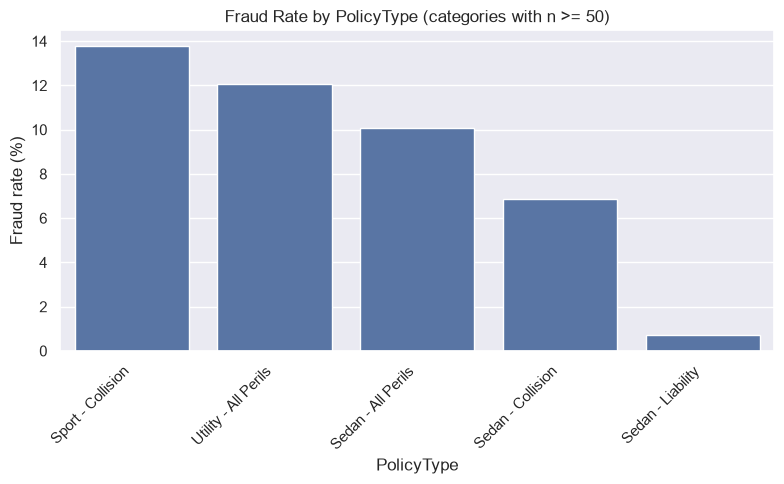

,claim_count,fraud_rate_pct
PolicyType,,
Sport - Collision,348,13.793103
Utility - All Perils,340,12.058824
Sedan - All Perils,4087,10.056276
Sedan - Collision,5584,6.876791
Sedan - Liability,4987,0.721877


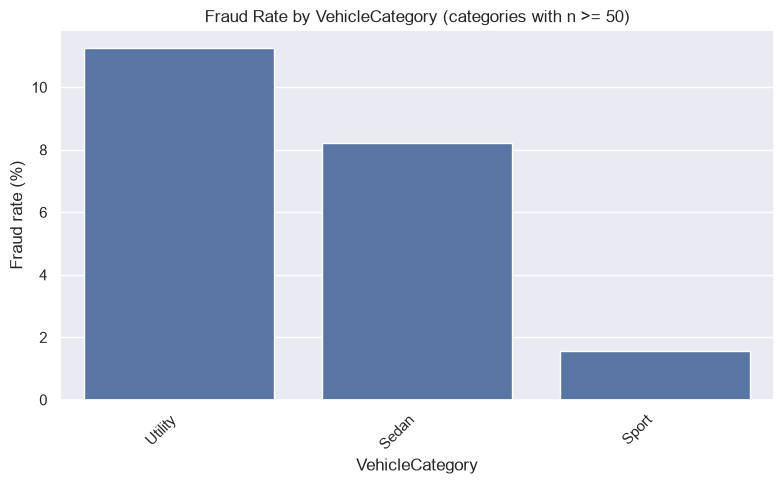

,claim_count,fraud_rate_pct
VehicleCategory,,
Utility,391,11.253197
Sedan,9671,8.220453
Sport,5358,1.567749


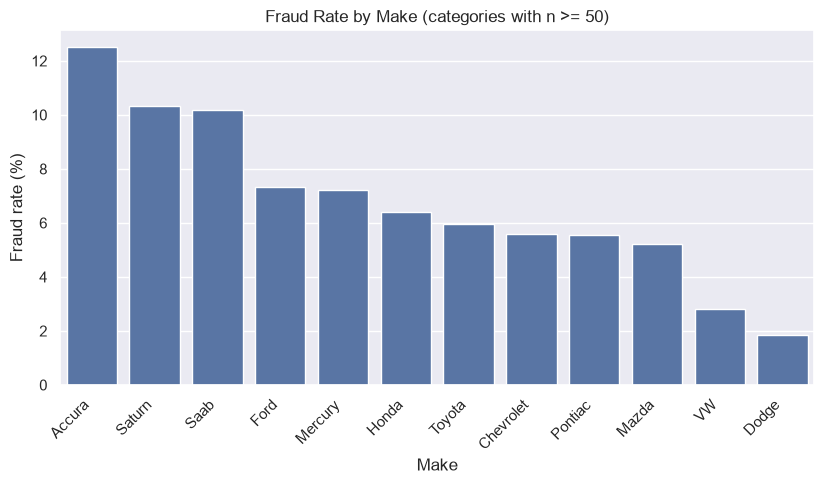

,claim_count,fraud_rate_pct
Make,,
Accura,472,12.500000
Saturn,58,10.344828
Saab,108,10.185185
Ford,450,7.333333
Mercury,83,7.228916
Honda,2801,6.390575
Toyota,3121,5.959628
Chevrolet,1681,5.591910
Pontiac,3837,5.551212


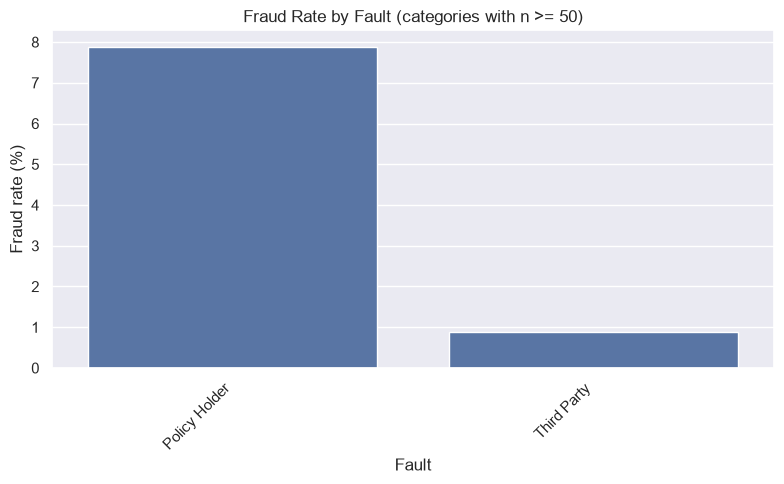

,claim_count,fraud_rate_pct
Fault,,
Policy Holder,11230,7.889581
Third Party,4190,0.883055


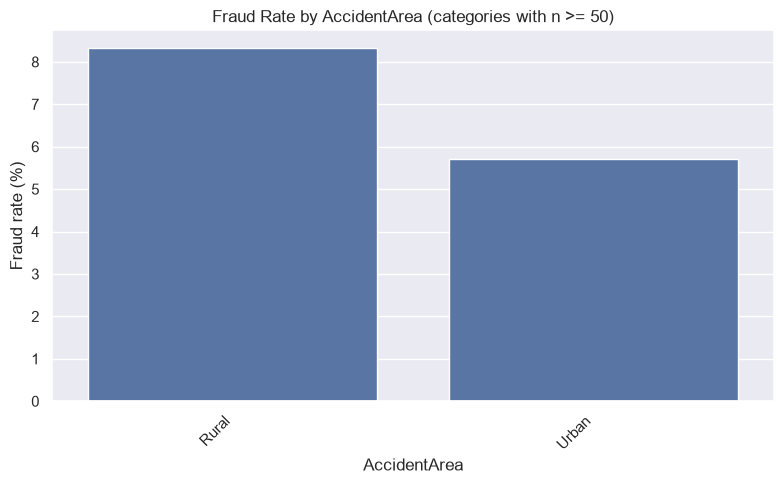

,claim_count,fraud_rate_pct
AccidentArea,,
Rural,1598,8.322904
Urban,13822,5.715526


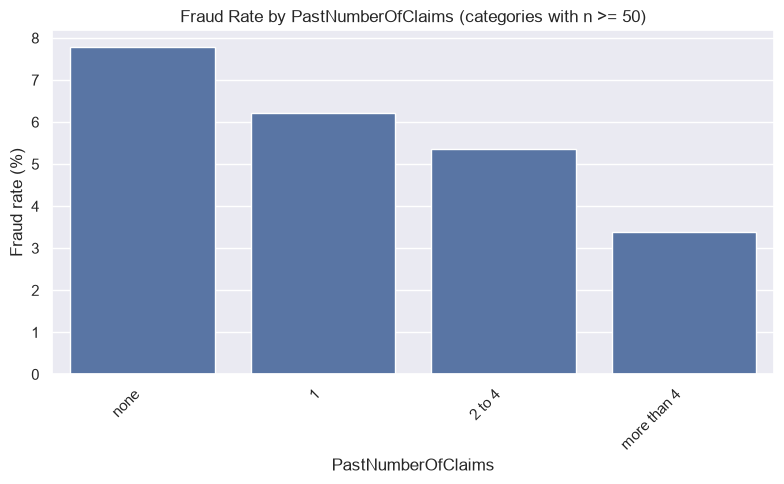

,claim_count,fraud_rate_pct
PastNumberOfClaims,,
none,4352,7.789522
1,3573,6.213266
2 to 4,5485,5.360073
more than 4,2010,3.383085


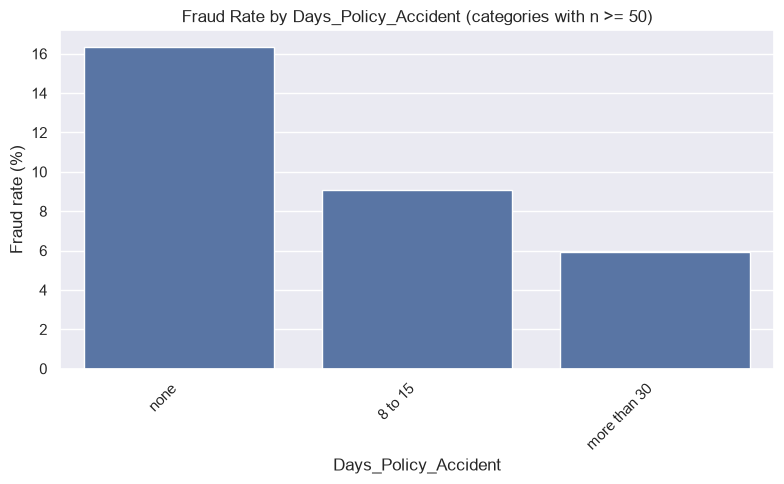

,claim_count,fraud_rate_pct
Days_Policy_Accident,,
none,55,16.363636
8 to 15,55,9.090909
more than 30,15247,5.935594


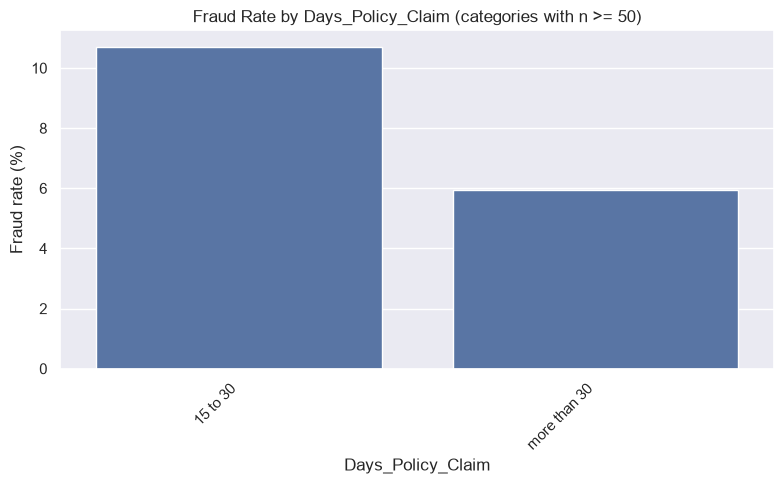

,claim_count,fraud_rate_pct
Days_Policy_Claim,,
15 to 30,56,10.714286
more than 30,15342,5.957502


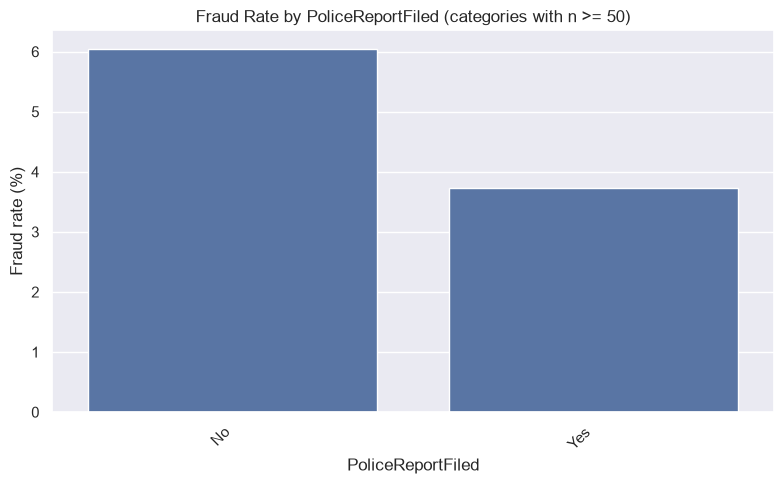

,claim_count,fraud_rate_pct
PoliceReportFiled,,
No,14992,6.049893
Yes,428,3.738318


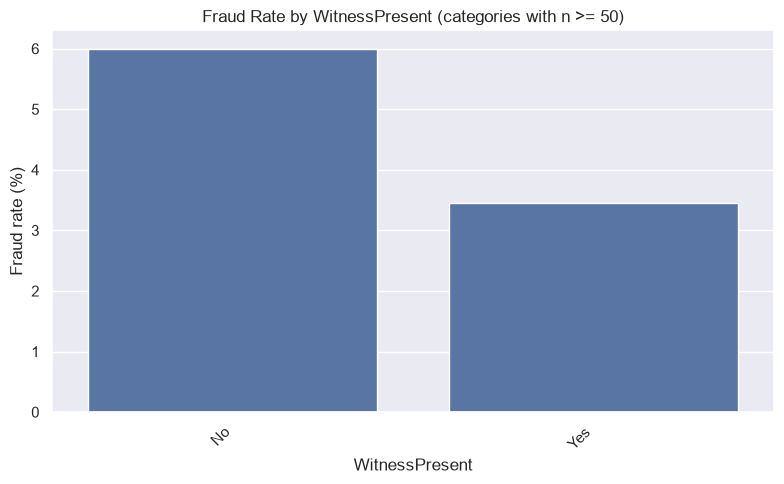

,claim_count,fraud_rate_pct
WitnessPresent,,
No,15333,6.000130
Yes,87,3.448276


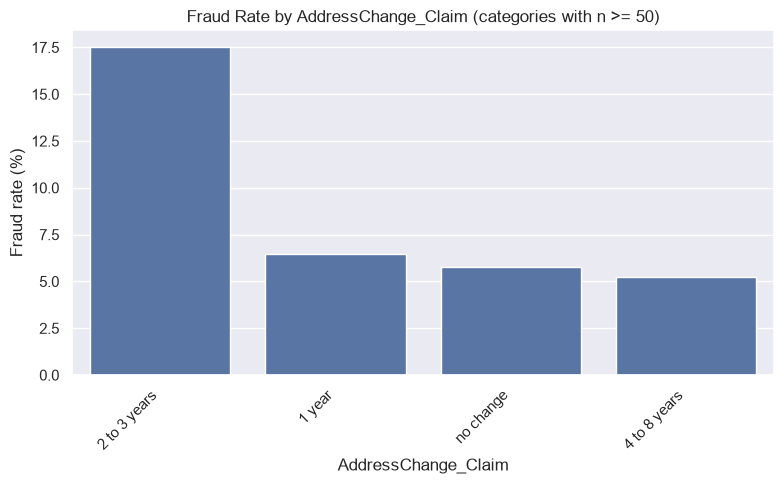

,claim_count,fraud_rate_pct
AddressChange_Claim,,
2 to 3 years,291,17.525773
1 year,170,6.470588
no change,14324,5.759564
4 to 8 years,631,5.229794


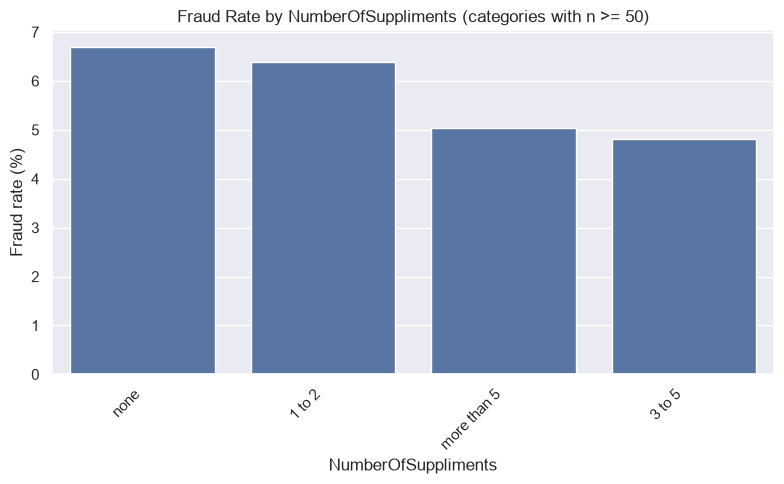

,claim_count,fraud_rate_pct
NumberOfSuppliments,,
none,7047,6.697886
1 to 2,2489,6.388108
more than 5,3867,5.042669
3 to 5,2017,4.809122


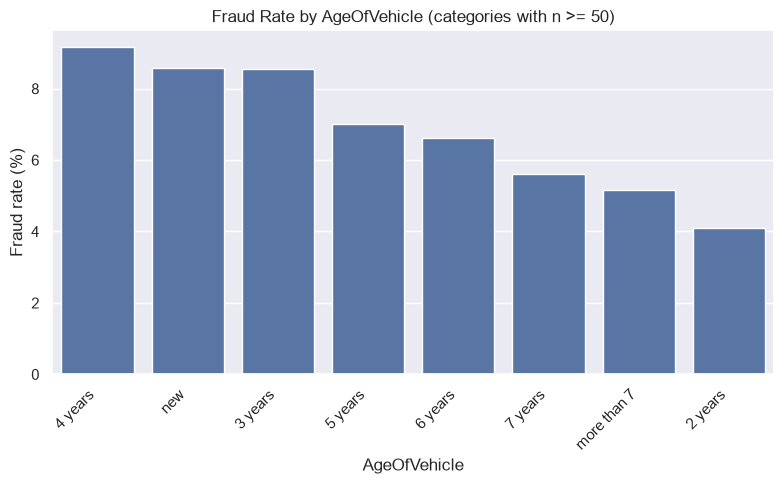

,claim_count,fraud_rate_pct
AgeOfVehicle,,
4 years,229,9.170306
new,373,8.579088
3 years,152,8.552632
5 years,1357,7.000737
6 years,3448,6.612529
7 years,5807,5.596694
more than 7,3981,5.174579
2 years,73,4.109589


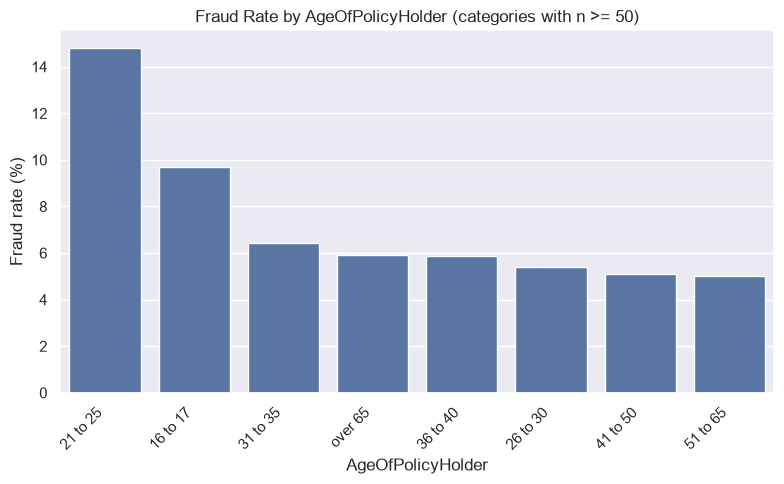

,claim_count,fraud_rate_pct
AgeOfPolicyHolder,,
21 to 25,108,14.814815
16 to 17,320,9.687500
31 to 35,5593,6.436617
over 65,508,5.905512
36 to 40,4043,5.861984
26 to 30,613,5.383361
41 to 50,2828,5.091938
51 to 65,1392,5.028736


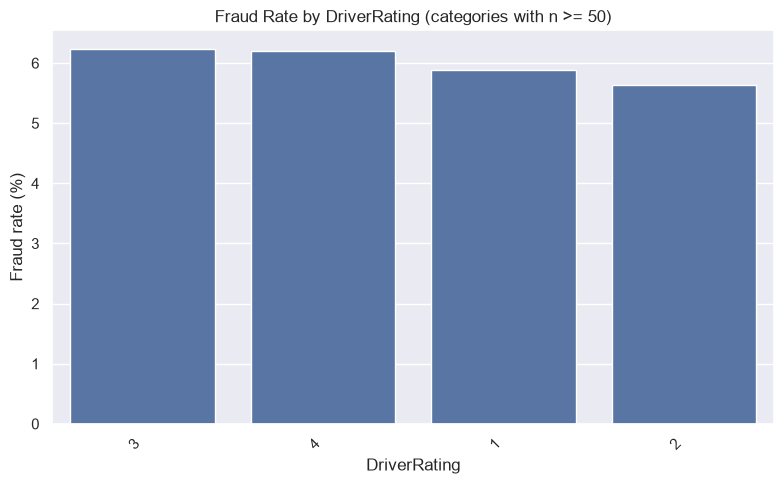

,claim_count,fraud_rate_pct
DriverRating,,
3,3884,6.230690
4,3791,6.198892
1,3944,5.882353
2,3801,5.630097


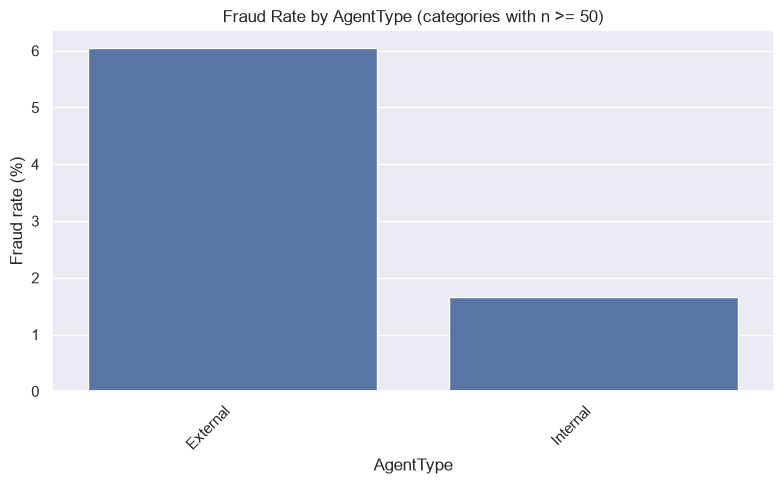

,claim_count,fraud_rate_pct
AgentType,,
External,15179,6.054417
Internal,241,1.659751


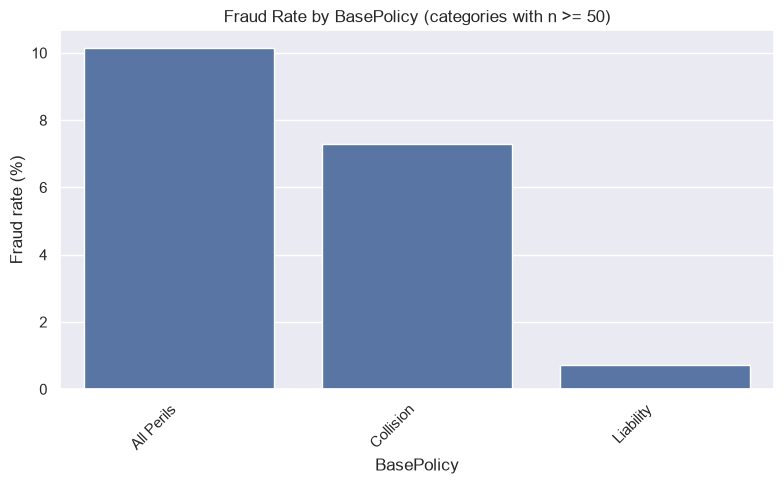

,claim_count,fraud_rate_pct
BasePolicy,,
All Perils,4449,10.159586
Collision,5962,7.296209
Liability,5009,0.718706


In [6]:
selected_categorical_features = [
    "PolicyType", "VehicleCategory", "Make", "Fault", "AccidentArea",
    "PastNumberOfClaims", "Days_Policy_Accident", "Days_Policy_Claim",
    "PoliceReportFiled", "WitnessPresent", "AddressChange_Claim",
    "NumberOfSuppliments", "AgeOfVehicle", "AgeOfPolicyHolder",
    "DriverRating", "AgentType", "BasePolicy"
]
selected_categorical_features = [f for f in selected_categorical_features if f in df.columns]

for feature in selected_categorical_features:
    plot_df = (df.groupby(feature, dropna=False)[TARGET]
                 .agg(claim_count="size", fraud_rate="mean")
                 .query("claim_count >= @MIN_CATEGORY_COUNT")
                 .sort_values("fraud_rate", ascending=False))
    if plot_df.empty:
        print(f"Skipping {feature}: no categories meet minimum support")
        continue
    plt.figure(figsize=(max(8, len(plot_df) * 0.7), 5))
    ax = sns.barplot(x=plot_df.index.astype(str), y=plot_df["fraud_rate"] * 100)
    ax.set_title(f"Fraud Rate by {feature} (categories with n >= {MIN_CATEGORY_COUNT})")
    ax.set_ylabel("Fraud rate (%)")
    ax.set_xlabel(feature)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
    display(plot_df.assign(fraud_rate_pct=plot_df.fraud_rate*100).drop(columns="fraud_rate"))

## 5. Numeric features: distributions and group comparison

Numeric columns include true numeric measurements and integer-coded variables. We will examine distributions and compare fraud groups, but avoid treating IDs as meaningful continuous features.

In [7]:
numeric_features = df.select_dtypes(include=[np.number]).columns.tolist()
exclude_numeric = {TARGET, "PolicyNumber", "RepNumber", "Year"}
numeric_features_for_eda = [c for c in numeric_features if c not in exclude_numeric]

print("Numeric features examined:", numeric_features_for_eda)
display(df[numeric_features_for_eda].describe().T)

Numeric features examined: ['WeekOfMonth', 'WeekOfMonthClaimed', 'Age', 'Deductible', 'DriverRating']


,count,mean,std,min,25%,50%,75%,max
WeekOfMonth,15420.0,2.788586,1.287585,1.0,2.0,3.0,4.0,5.0
WeekOfMonthClaimed,15420.0,2.693969,1.259115,1.0,2.0,3.0,4.0,5.0
Age,15420.0,39.855707,13.492377,0.0,31.0,38.0,48.0,80.0
Deductible,15420.0,407.704280,43.950998,300.0,400.0,400.0,400.0,700.0
DriverRating,15420.0,2.487808,1.119453,1.0,1.0,2.0,3.0,4.0


### 5.1 Fraud vs. legitimate summary statistics

In [8]:
group_numeric_summary = df.groupby(TARGET)[numeric_features_for_eda].agg(["mean", "median", "std"])
display(group_numeric_summary)

WeekOfMonth                  WeekOfMonthClaimed                   \
                    mean median       std               mean median       std   
FraudFound_P                                                                    
0               2.792440    3.0  1.287957           2.695799    3.0  1.259360   
1               2.728061    3.0  1.280906           2.665222    3.0  1.255596   

                    Age                    Deductible                    \
                   mean median        std        mean median        std   
FraudFound_P                                                              
0             39.956957   38.0  13.462013  407.511899  400.0  43.770260   
1             38.265439   36.0  13.871426  410.725894  400.0  46.619027   

             DriverRating                   
                     mean median       std  
FraudFound_P                                
0                2.485756    2.0  1.119184  
1                2.520043    3.0  1.123781

### 5.2 Distribution plots for numeric features

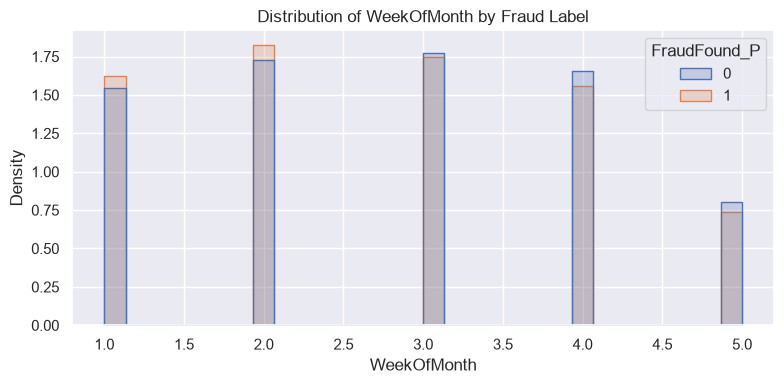

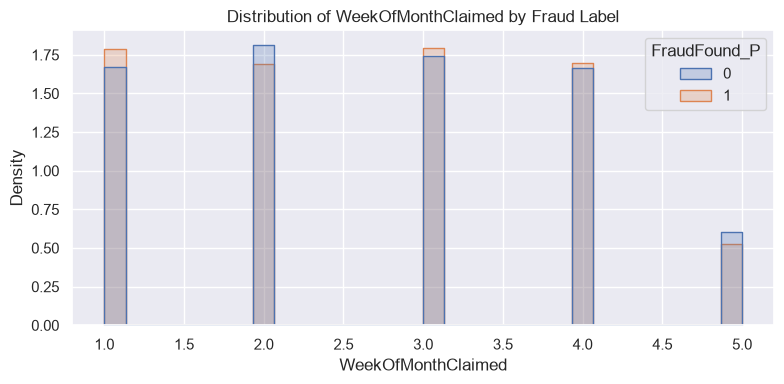

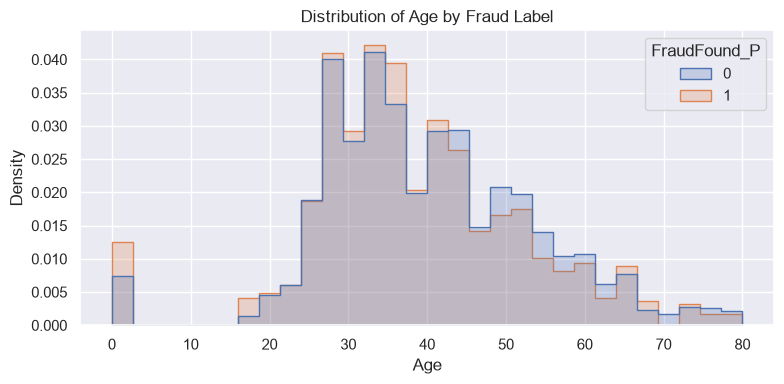

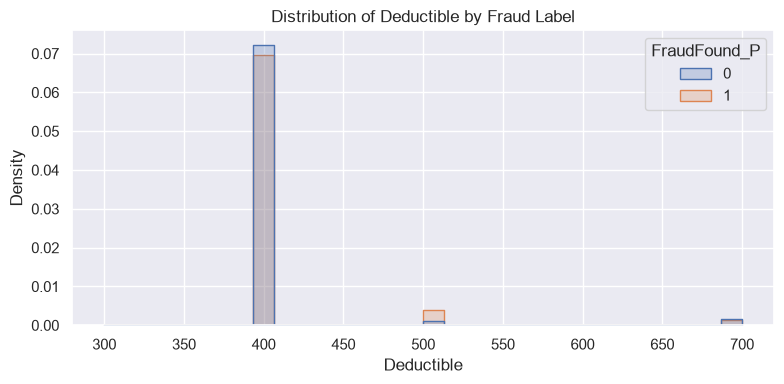

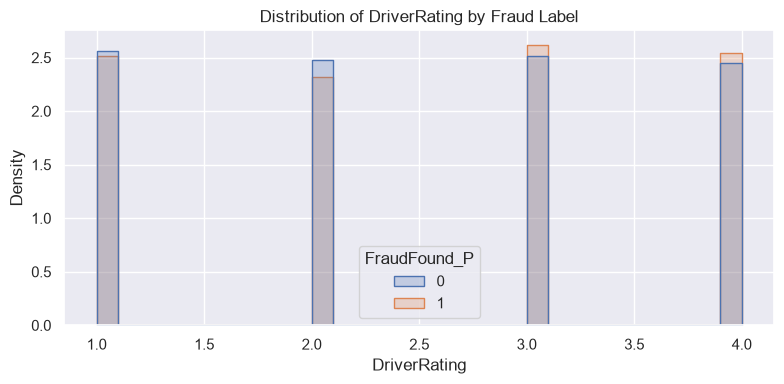

In [9]:
for feature in numeric_features_for_eda:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=df, x=feature, hue=TARGET, bins=30, stat="density", common_norm=False,
                 element="step", kde=False)
    plt.title(f"Distribution of {feature} by Fraud Label")
    plt.tight_layout()
    plt.show()

## 6. Claimant age analysis

Age is numeric, so we can examine it in ranges. The bins are exploratory and should not be interpreted as evidence of fraud or used as a decision rule without fairness and business review.

,claim_count,fraud_count,fraud_rate,fraud_rate_pct
AgeGroup_EDA,,,,
<=17,335,33,0.098507,9.850746
18-20,108,16,0.148148,14.814815
21-25,613,33,0.053834,5.383361
26-30,2783,170,0.061085,6.108516
31-35,2810,190,0.067616,6.761566
36-40,2018,127,0.062934,6.293360
41-50,3475,186,0.053525,5.352518
51-65,2770,138,0.049819,4.981949
66+,508,30,0.059055,5.905512


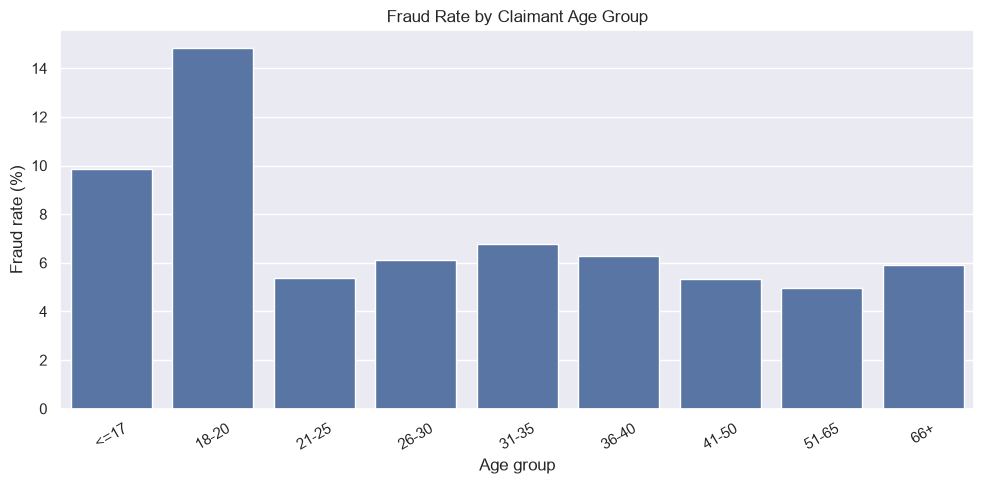

In [10]:
age_bins = [0, 17, 20, 25, 30, 35, 40, 50, 65, 100]
age_labels = ["<=17", "18-20", "21-25", "26-30", "31-35", "36-40", "41-50", "51-65", "66+"]
df["AgeGroup_EDA"] = pd.cut(df["Age"], bins=age_bins, labels=age_labels, include_lowest=True)
age_summary = (df.groupby("AgeGroup_EDA", observed=False)[TARGET]
                .agg(claim_count="size", fraud_count="sum", fraud_rate="mean"))
age_summary["fraud_rate_pct"] = age_summary["fraud_rate"] * 100
display(age_summary)

plt.figure(figsize=(10, 5))
sns.barplot(data=age_summary.reset_index(), x="AgeGroup_EDA", y="fraud_rate_pct")
plt.title("Fraud Rate by Claimant Age Group")
plt.xlabel("Age group")
plt.ylabel("Fraud rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 7. Accident timing vs. claim timing

The dataset contains accident timing fields and claim timing fields. We will compare month/day distributions, and specifically inspect placeholder values such as `0` that may represent unknown or invalid values. Do not assume claim lag can be calculated exactly from these fields because the dataset may not contain complete dates.

In [11]:
timing_features = [c for c in ["Month", "DayOfWeek", "MonthClaimed", "DayOfWeekClaimed",
                                "WeekOfMonth", "WeekOfMonthClaimed", "Year"] if c in df.columns]
for feature in timing_features:
    print(f"\n{feature} — value counts")
    display(df[feature].value_counts(dropna=False).to_frame("count"))


Month — value counts


,count
Month,
Jan,1411
May,1367
Mar,1360
Jun,1321
Oct,1305
Dec,1285
Apr,1280
Feb,1266
Jul,1257



DayOfWeek — value counts


,count
DayOfWeek,
Monday,2616
Friday,2445
Tuesday,2300
Thursday,2173
Wednesday,2159
Saturday,1982
Sunday,1745



MonthClaimed — value counts


,count
MonthClaimed,
Jan,1446
May,1411
Mar,1348
Oct,1339
Jun,1293
Feb,1287
Nov,1285
Apr,1271
Sep,1242


... (4 outputs left out)


WeekOfMonthClaimed — value counts


,count
WeekOfMonthClaimed,
2,3720
3,3583
1,3450
4,3433
5,1234



Year — value counts


,count
Year,
1994,6142
1995,5195
1996,4083


### 7.1 Fraud rates by timing variables

,claim_count,fraud_rate,fraud_rate_pct
Month,,,
Mar,1360,0.075000,7.500000
Aug,1127,0.074534,7.453416
May,1367,0.068764,6.876372
Feb,1266,0.064771,6.477093
Apr,1280,0.062500,6.250000
Jan,1411,0.061658,6.165840
Sep,1240,0.061290,6.129032
Jun,1321,0.060560,6.056018
Oct,1305,0.053640,5.363985


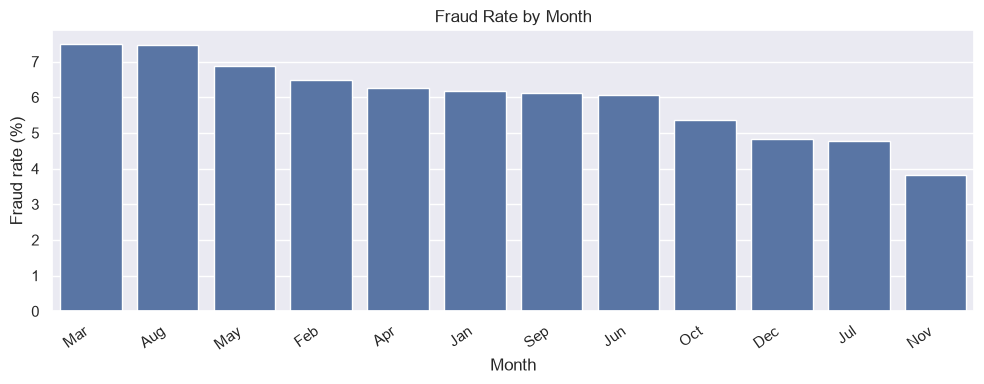

,claim_count,fraud_rate,fraud_rate_pct
DayOfWeek,,,
Sunday,1745,0.069914,6.991404
Saturday,1982,0.066599,6.659939
Friday,2445,0.062986,6.298569
Monday,2616,0.061162,6.116208
Thursday,2173,0.055223,5.522319
Wednesday,2159,0.053265,5.326540
Tuesday,2300,0.052174,5.217391


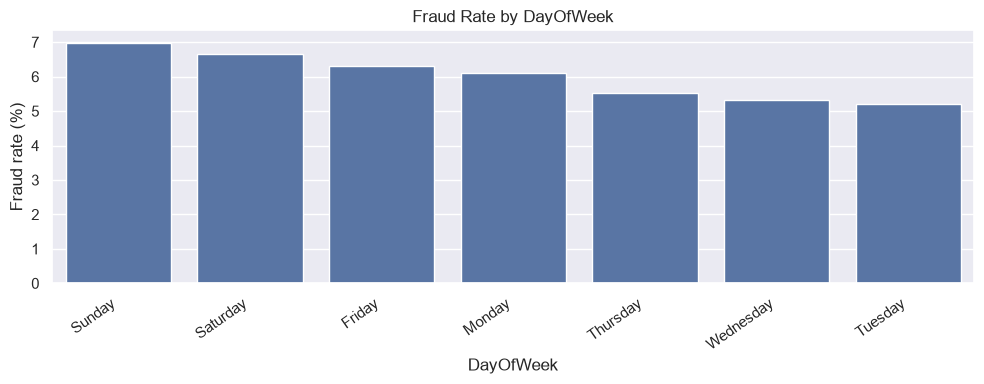

,claim_count,fraud_rate,fraud_rate_pct
MonthClaimed,,,
Aug,1126,0.081705,8.170515
May,1411,0.072289,7.228916
Mar,1348,0.071958,7.195846
Apr,1271,0.064516,6.451613
Jan,1446,0.063624,6.362379
Sep,1242,0.062802,6.280193
Feb,1287,0.060606,6.060606
Jun,1293,0.060325,6.032483
Oct,1339,0.054518,5.451830


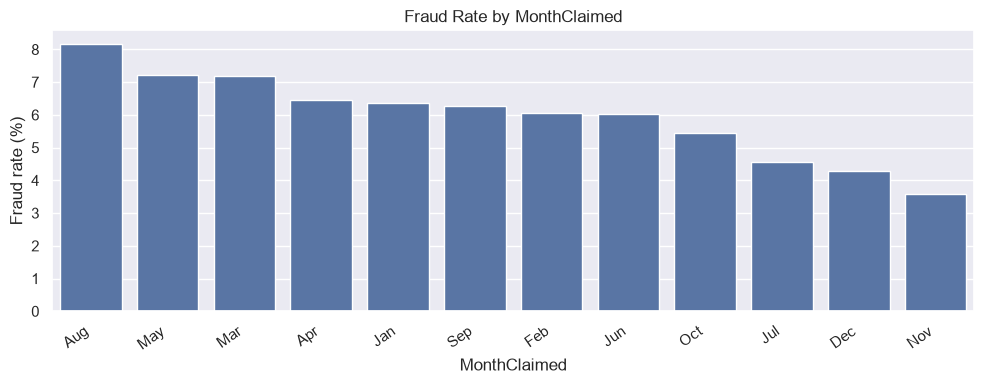

,claim_count,fraud_rate,fraud_rate_pct
DayOfWeekClaimed,,,
Saturday,127,0.078740,7.874016
Friday,2497,0.065679,6.567881
Wednesday,2951,0.063707,6.370722
Tuesday,3375,0.058667,5.866667
Sunday,52,0.057692,5.769231
Monday,3757,0.057493,5.749268
Thursday,2660,0.054135,5.413534


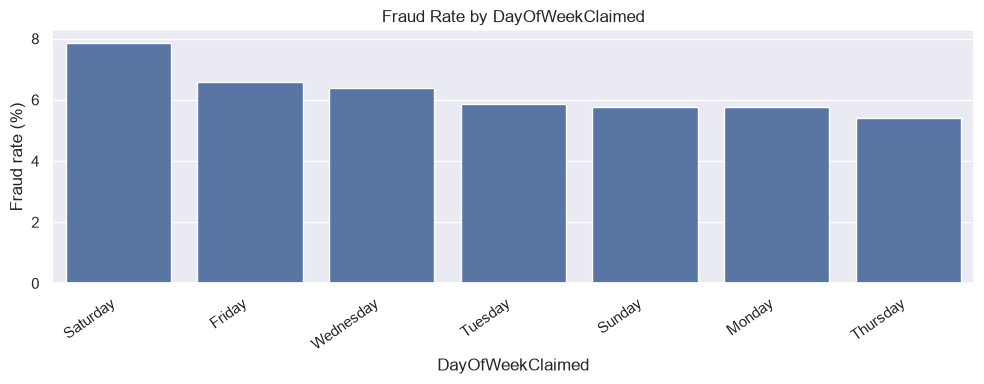

,claim_count,fraud_rate,fraud_rate_pct
WeekOfMonth,,,
2,3558,0.063238,6.323777
1,3187,0.062755,6.275494
3,3640,0.059066,5.906593
4,3398,0.056504,5.650383
5,1637,0.055589,5.558949


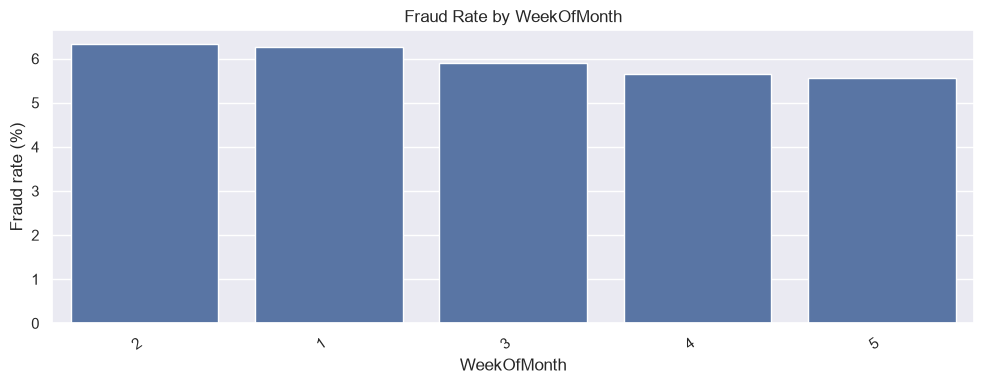

,claim_count,fraud_rate,fraud_rate_pct
WeekOfMonthClaimed,,,
1,3450,0.063768,6.376812
3,3583,0.061680,6.168016
4,3433,0.060880,6.087970
2,3720,0.055914,5.591398
5,1234,0.052674,5.267423


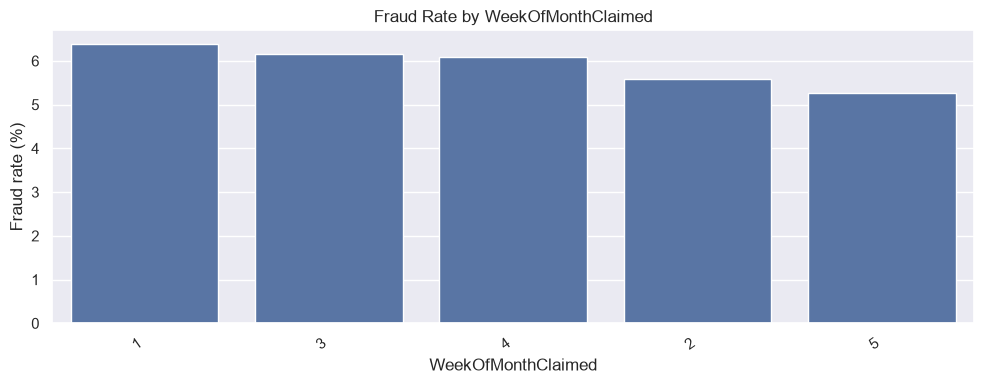

In [12]:
for feature in ["Month", "DayOfWeek", "MonthClaimed", "DayOfWeekClaimed", "WeekOfMonth", "WeekOfMonthClaimed"]:
    if feature not in df.columns:
        continue
    summary = df.groupby(feature, dropna=False)[TARGET].agg(claim_count="size", fraud_rate="mean")
    summary = summary[summary.claim_count >= MIN_CATEGORY_COUNT].sort_values("fraud_rate", ascending=False)
    if not summary.empty:
        display(summary.assign(fraud_rate_pct=summary.fraud_rate*100))
        plt.figure(figsize=(10, 4))
        sns.barplot(x=summary.index.astype(str), y=summary.fraud_rate*100)
        plt.title(f"Fraud Rate by {feature}")
        plt.ylabel("Fraud rate (%)")
        plt.xticks(rotation=35, ha="right")
        plt.tight_layout()
        plt.show()

## 8. Claim-history and documentation indicators

Explore features such as prior claims, police report, witness presence, supplements, address changes and number of vehicles. These are descriptive associations only; missing documentation or unusual patterns are not proof of fraud.

In [13]:
history_document_features = [c for c in ["PastNumberOfClaims", "PoliceReportFiled", "WitnessPresent",
                                           "NumberOfSuppliments", "AddressChange_Claim", "NumberOfCars",
                                           "Days_Policy_Accident", "Days_Policy_Claim"] if c in df.columns]
for feature in history_document_features:
    summary = df.groupby(feature, dropna=False)[TARGET].agg(claim_count="size", fraud_count="sum", fraud_rate="mean")
    summary["fraud_rate_pct"] = summary["fraud_rate"] * 100
    display(summary.sort_values("fraud_rate", ascending=False).style.format({"fraud_rate":"{:.3f}", "fraud_rate_pct":"{:.2f}%"}))

,claim_count,fraud_count,fraud_rate,fraud_rate_pct
PastNumberOfClaims,,,,
none,4352,339,0.078,7.79%
1,3573,222,0.062,6.21%
2 to 4,5485,294,0.054,5.36%
more than 4,2010,68,0.034,3.38%


,claim_count,fraud_count,fraud_rate,fraud_rate_pct
PoliceReportFiled,,,,
No,14992,907,0.060,6.05%
Yes,428,16,0.037,3.74%


,claim_count,fraud_count,fraud_rate,fraud_rate_pct
WitnessPresent,,,,
No,15333,920,0.060,6.00%
Yes,87,3,0.034,3.45%


,claim_count,fraud_count,fraud_rate,fraud_rate_pct
NumberOfSuppliments,,,,
none,7047,472,0.067,6.70%
1 to 2,2489,159,0.064,6.39%
more than 5,3867,195,0.050,5.04%
3 to 5,2017,97,0.048,4.81%


,claim_count,fraud_count,fraud_rate,fraud_rate_pct
AddressChange_Claim,,,,
under 6 months,4,3,0.750,75.00%
2 to 3 years,291,51,0.175,17.53%
1 year,170,11,0.065,6.47%
no change,14324,825,0.058,5.76%
4 to 8 years,631,33,0.052,5.23%


,claim_count,fraud_count,fraud_rate,fraud_rate_pct
NumberOfCars,,,,
3 to 4,372,29,0.078,7.80%
2 vehicles,709,43,0.061,6.06%
1 vehicle,14316,850,0.059,5.94%
5 to 8,21,1,0.048,4.76%
more than 8,2,0,0.000,0.00%


,claim_count,fraud_count,fraud_rate,fraud_rate_pct
Days_Policy_Accident,,,,
none,55,9,0.164,16.36%
8 to 15,55,5,0.091,9.09%
1 to 7,14,1,0.071,7.14%
15 to 30,49,3,0.061,6.12%
more than 30,15247,905,0.059,5.94%


,claim_count,fraud_count,fraud_rate,fraud_rate_pct
Days_Policy_Claim,,,,
8 to 15,21,3,0.143,14.29%
15 to 30,56,6,0.107,10.71%
more than 30,15342,914,0.060,5.96%
none,1,0,0.000,0.00%


## 9. Compare fraud rates with the overall prevalence

This view helps identify categories whose observed fraud rate is above or below the dataset-wide rate. Use counts alongside rates; small groups can have extreme rates by chance.

In [14]:
overall_rate = df[TARGET].mean()

# Build a long table for selected features, excluding tiny groups.
comparison_rows = []
for feature in selected_categorical_features:
    summary = df.groupby(feature, dropna=False)[TARGET].agg(claim_count="size", fraud_count="sum", fraud_rate="mean")
    for category, row in summary.iterrows():
        if row["claim_count"] >= MIN_CATEGORY_COUNT:
            comparison_rows.append({
                "feature": feature, "category": str(category), "claim_count": int(row["claim_count"]),
                "fraud_count": int(row["fraud_count"]), "fraud_rate": row["fraud_rate"],
                "lift_vs_overall": row["fraud_rate"] / overall_rate if overall_rate else np.nan
            })
comparison = pd.DataFrame(comparison_rows)
comparison = comparison.sort_values("lift_vs_overall", ascending=False)
display(comparison.head(30))

,feature,category,claim_count,fraud_count,fraud_rate,lift_vs_overall
38,AddressChange_Claim,2 to 3 years,291,51,0.175258,2.927924
30,Days_Policy_Accident,none,55,9,0.163636,2.733773
54,AgeOfPolicyHolder,21 to 25,108,16,0.148148,2.475021
3,PolicyType,Sport - Collision,348,48,0.137931,2.304330
8,Make,Accura,472,59,0.125000,2.088299
4,PolicyType,Utility - All Perils,340,41,0.120588,2.014594
7,VehicleCategory,Utility,391,44,0.112532,1.880003
31,Days_Policy_Claim,15 to 30,56,6,0.107143,1.789971
17,Make,Saturn,58,6,0.103448,1.728247
16,Make,Saab,108,11,0.101852,1.701577


## 10. Save EDA outputs

Save selected summary tables as CSV to the reports directory so results can be tracked and reused.

In [16]:
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
comparison.to_csv(REPORTS_DIR / "categorical_fraud_rate_comparison.csv", index=False)
target_summary.to_csv(REPORTS_DIR / "target_distribution.csv")
print("Saved summary tables to:", REPORTS_DIR)

Saved summary tables to: c:\Users\rudra\OneDrive\Documents\insurance-claim-fraud-detection\insurance-claim-fraud-detection\reports


## 12. EDA conclusion

The exploratory data analysis revealed several patterns associated with fraudulent insurance claims in our dataset of 15,420 records. Fraud represents approximately **5.99% of all claims**, confirming a significant class imbalance that will need to be addressed during model development.

### Key Findings

1. **Fraud is associated with certain policy and vehicle categories.** Fraud rates vary considerably across policy types, vehicle categories, and base policy categories. For example, the observed fraud rate is higher for certain All Perils and Collision policy groups than for Liability policies.

2. **Fault-related patterns show a notable difference.** Claims where the policyholder was recorded as at fault have a higher observed fraud rate than claims involving third-party fault. This variable may be useful for predictive modelling, although its availability and timing must be validated.

3. **Some claim and accident timing categories exhibit elevated fraud rates.** Certain combinations of accident-to-policy timing and claim timing show higher observed fraud prevalence. However, some of these categories contain relatively few observations, so their rates may be unstable.

4. **Claim history presents an interesting pattern.** Claims with no previous claims recorded exhibit a higher fraud rate than some categories with prior claims. This challenges the assumption that repeat claimants are always more suspicious and highlights the need to validate individual hypotheses using the data.

5. **Vehicle and policyholder characteristics show differences.** Fraud rates vary across vehicle makes, vehicle age categories, and policyholder age groups. These variables may help the model capture patterns, but should be evaluated carefully for reliability, bias, and practical relevance.

6. **Supporting documentation variables show mixed patterns.** The presence or absence of police reports and witnesses is associated with different fraud rates. However, these variables should not be used independently as evidence of fraud and may reflect reporting or claim-handling processes.

### Modelling Implications

- Fraud detection will require handling significant class imbalance.
- Categorical variables appear important and should be encoded appropriately.
- Feature engineering may help capture interactions between policy, accident, vehicle, and claim characteristics.
- Variables with small category sample sizes should be treated cautiously.
- We should avoid using identifiers such as PolicyNumber as predictive features without justification.
- Potential data leakage and the timing of feature availability must be examined before modelling.
- Model performance should be evaluated using precision, recall, PR-AUC, and our operational KPI of Precision@200 and Recall@200.

### Final Conclusion

The EDA suggests that fraud detection is not driven by a single variable but by patterns across policy characteristics, accident circumstances, vehicle information, claim history, and supporting documentation. These insights provide a foundation for feature engineering and predictive modelling. The next step is to transform these observations into meaningful features while ensuring data quality, avoiding leakage, and preserving the interpretability of the fraud detection system.